In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = 'C:/Users/LC130XXXX/Desktop/3.3.2 turbines_df.csv'
df = pd.read_csv(url, sep = ',')

In [3]:
df

,turbine_capacity,rotor_diameter_m,hub_height_m,commissioning_date,province_territory,model
0,150,23.0,30.0,1993,Alberta,Other
1,600,44.0,40.0,1997,Alberta,Other
2,600,44.0,50.0,1998,Alberta,Other
3,600,44.0,50.0,1998,Alberta,Other
4,600,44.0,50.0,1998,Alberta,Other
...,...,...,...,...,...,...
6473,660,47.0,50.0,2001,Saskatchewan,Other
6474,660,47.0,50.0,2001,Saskatchewan,Other
6475,660,47.0,50.0,2001,Saskatchewan,Other
6476,150,23.0,30.0,1993,Other,Other


In [6]:
df.head()

,turbine_capacity,rotor_diameter_m,hub_height_m,commissioning_date,province_territory,model
0,150,23.0,30.0,1993,Alberta,Other
1,600,44.0,40.0,1997,Alberta,Other
2,600,44.0,50.0,1998,Alberta,Other
3,600,44.0,50.0,1998,Alberta,Other
4,600,44.0,50.0,1998,Alberta,Other


In [7]:
df.tail()

,turbine_capacity,rotor_diameter_m,hub_height_m,commissioning_date,province_territory,model
6473,660,47.0,50.0,2001,Saskatchewan,Other
6474,660,47.0,50.0,2001,Saskatchewan,Other
6475,660,47.0,50.0,2001,Saskatchewan,Other
6476,150,23.0,30.0,1993,Other,Other
6477,660,47.0,37.0,2000,Other,Other


In [8]:
df.sample()

,turbine_capacity,rotor_diameter_m,hub_height_m,commissioning_date,province_territory,model
4992,2300,82.0,98.0,2012,Quebec,E-82


In [29]:
df.shape

(6478, 6)

In [9]:
df.isnull().sum()

turbine_capacity      0
rotor_diameter_m      0
hub_height_m          0
commissioning_date    0
province_territory    0
model                 0
dtype: int64

In [15]:
df.columns.tolist()

['turbine_capacity',
 'rotor_diameter_m',
 'hub_height_m',
 'commissioning_date',
 'province_territory',
 'model']

In [16]:
df.dtypes

turbine_capacity        int64
rotor_diameter_m      float64
hub_height_m          float64
commissioning_date      int64
province_territory     object
model                  object
dtype: object

In [19]:
df['province_territory'].unique().tolist()

['Alberta',
 'British Columbia',
 'Manitoba',
 'New Brunswick',
 'Newfoundland and Labrador',
 'Other',
 'Nova Scotia',
 'Ontario',
 'Prince Edward Island',
 'Quebec',
 'Saskatchewan']

In [20]:
df['model'].unique().tolist()

['Other',
 'V47/660',
 'GE 1.5SLE',
 'GE 1.6-100',
 'V90/1800',
 'SWT 2.3-101',
 'E-82',
 'V82/1650',
 'MM92',
 'MM82',
 'V80']

In [22]:
df.describe()

,turbine_capacity,rotor_diameter_m,hub_height_m,commissioning_date
count,6478.000000,6478.000000,6478.000000,6478.000000
mean,1967.307194,88.203520,82.790908,2011.019142
std,605.933839,16.566686,14.366232,4.340453
min,65.000000,15.000000,24.500000,1993.000000
25%,1600.000000,77.000000,80.000000,2009.000000
50%,1880.000000,90.000000,80.000000,2012.000000
75%,2300.000000,100.000000,85.000000,2014.000000
max,3750.000000,141.000000,132.000000,2019.000000


In [25]:
df.describe(include = 'object')

,province_territory,model
count,6478,6478
unique,11,11
top,Ontario,Other
freq,2443,2789


In [27]:
for x in df.columns:
    print('La cantidad de nulos en la característica', x, 'es de',df[x].isna().sum())

La cantidad de nulos en la característica turbine_capacity es de 0
La cantidad de nulos en la característica rotor_diameter_m es de 0
La cantidad de nulos en la característica hub_height_m es de 0
La cantidad de nulos en la característica commissioning_date es de 0
La cantidad de nulos en la característica province_territory es de 0
La cantidad de nulos en la característica model es de 0


In [30]:
for x in df.columns:
    print('Las características son', x)

Las características son turbine_capacity
Las características son rotor_diameter_m
Las características son hub_height_m
Las características son commissioning_date
Las características son province_territory
Las características son model


In [32]:
df.corr()

,turbine_capacity,rotor_diameter_m,hub_height_m,commissioning_date
turbine_capacity,1.000000,0.748754,0.706078,0.655726
rotor_diameter_m,0.748754,1.000000,0.767204,0.803347
hub_height_m,0.706078,0.767204,1.000000,0.757478
commissioning_date,0.655726,0.803347,0.757478,1.000000


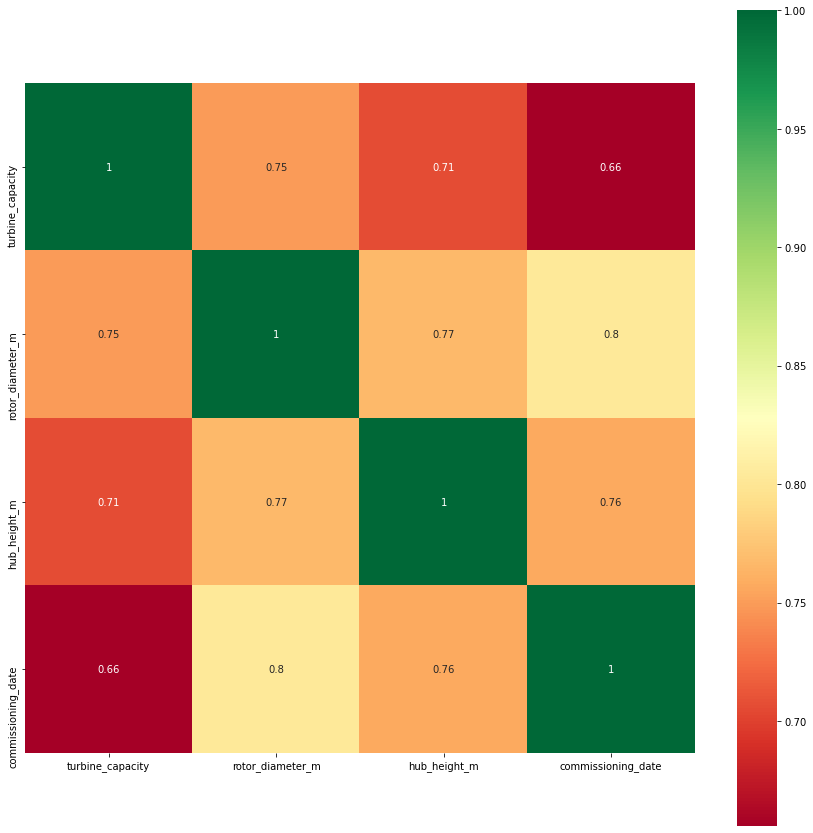

In [33]:
# Analizar la correlación de variables
plt.figure(figsize = (15,15))
p = sns.heatmap(df.corr(),annot = True, cmap = 'RdYlGn',square=True)

In [37]:
# Importamos librerías necesarias
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

In [39]:
X = df[['rotor_diameter_m','hub_height_m']]
y = df.turbine_capacity

# Entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state = 29)

modelo = DecisionTreeRegressor(max_depth = 5, random_state = 29)

# Entrenamos el modelo
modelo.fit(X_train,y_train)

# Creamos la prediccion

y_pred = modelo.predict(X_test)

# Evaluamos el modelo

print('La precisión del modelo (en entrenamiento) es:',
     modelo.score(X_train, y_train))


print('La precisión del modelo (en la validación) es:',
     modelo.score(X_test, y_test))

La precisión del modelo (en entrenamiento) es: 0.8249428738688777
La precisión del modelo (en la validación) es: 0.83418586620569


La profundidad del arbol es :  5
El numero de nodos terminales es :  26


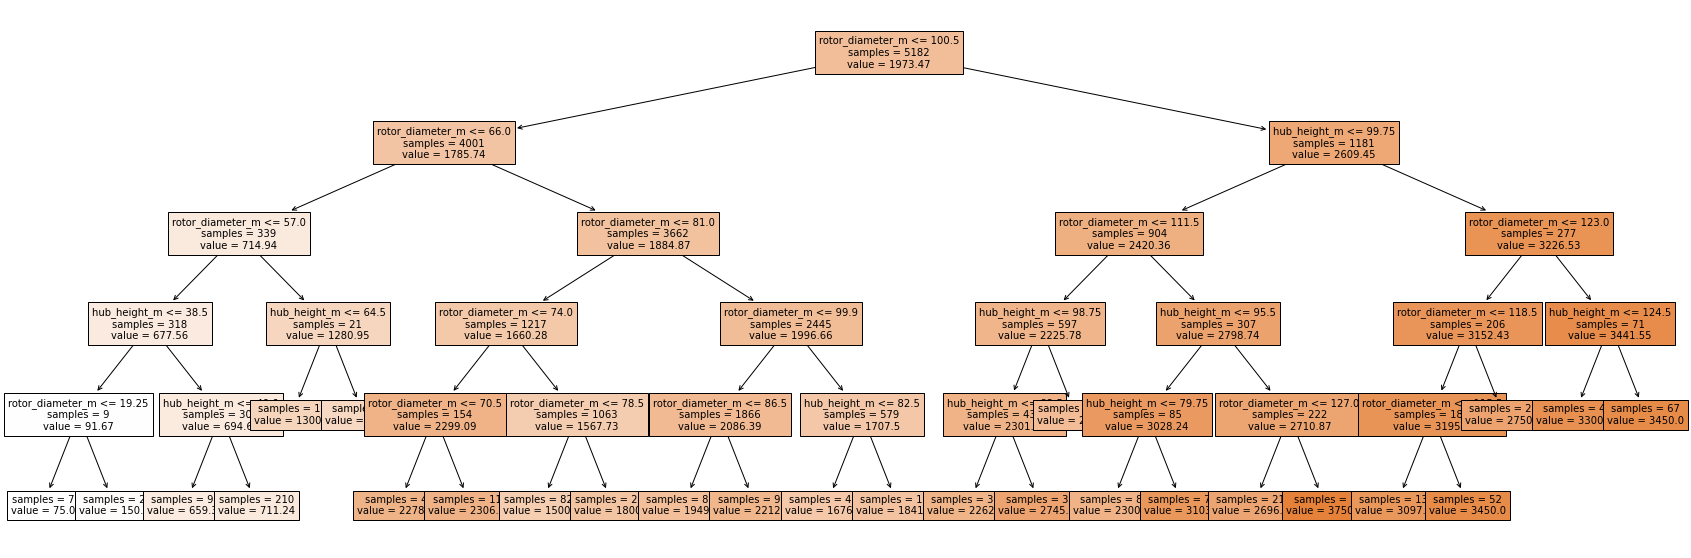

In [48]:
from sklearn.tree import plot_tree
fig , ax = plt.subplots(figsize = (30,10))

print(f"La profundidad del arbol es :  {modelo.get_depth()}")
print(f"El numero de nodos terminales es :  {modelo.get_n_leaves()}")

plot = plot_tree(
    decision_tree = modelo,
    feature_names = df.drop(columns=["province_territory","model","turbine_capacity"]).columns,
    class_names = "turbine_capacity",
    filled = True,
    impurity = False,
    fontsize = 10,
    precision = 2,
    ax = ax
)

In [49]:
# se ocupa cuando quiero tomar valores cuantitativos para evaluar una decisión